# 04 – Cross-dataset validation and per-cohort analysis
**Reproduces:** Section 5.1 (standardization, dataset documentation), Section 5.6 and Table 11 (per-cohort results), Section 5.7 and Table 12 (cross-dataset validation), Figure 2, Supplementary Tables S1–S4
**Responds to:** Reviewer 1 Comment 2; Reviewer 2 Comments 3 and 4; Reviewer 3 Comments 3 and 4

**Needs:** Cells 1–11 of 01_main_cold_drug.ipynb (copied below, unchanged); the folder `cross_dataset/` (our checkpoints and cached predictions);
`predictions/cold_drug_test_predictions_shipped_models.csv` (written by Cell 12 of 01_main_cold_drug.ipynb).

**Modes (Cell 12):** `MODE = "evaluate_saved"` (default) reads our cached predictions, or evaluates our checkpoints when a cache is missing; nothing is trained
and a CPU runtime is enough (about 20 minutes). `MODE = "train_and_evaluate"` retrains the cross-dataset models from scratch (3 seeds x 3 configurations, GPU strongly
recommended, several hours; use `XD_SEEDS = (42,)` for a quick check). Retrained files go to `cross_dataset_retrained/` and never overwrite ours.
All lines ending in "(paper: ...)" show the value reported in the manuscript next to the value computed here; ✓ means they agree.

In [ ]:
# ===== Cell 1: Environment =====
# Colab only. The package versions used for the reported results are pinned in requirements.txt.
!pip install -q rdkit matplotlib pubchempy torch torchvision torchaudio torch-geometric transformers xgboost

# Standard library
import io, json, os, sys
from pathlib import Path

# Numerics and data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, ttest_rel

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset

# Graph learning
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv
from torch_geometric.nn.aggr import AttentionalAggregation
from torch_geometric.utils import to_dense_batch

# Chemistry
from rdkit import Chem, RDLogger, Geometry
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import SimilarityMaps, rdMolDraw2D
from PIL import Image
from rdkit.Chem import Draw, rdDepictor


# Pretrained chemical language model (ChemBERTa)
from transformers import AutoTokenizer, AutoModel

# Classical ML and metrics
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import average_precision_score, mean_squared_error, roc_auc_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

RDLogger.DisableLog("rdApp.*")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.8 MB/s eta 0:00:00


In [ ]:
# ===== Cell 2: Configuration =====
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.ismount("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

# Project folder (see README): on Colab, upload the DualGATSynergy folder to your Drive or change this path.
ROOT = Path("/content/drive/MyDrive/DualGATSynergy") if IN_COLAB else Path(".")
DATA_DIR = ROOT / "data"

# --- Run mode (used in Cells 12 and 13) ---
MODE = "evaluate_saved"          # "evaluate_saved": load our trained models (no training; CPU is fine)
                                 # "train_and_evaluate": retrain from scratch (GPU recommended)
FOLDS_TO_RUN = [1, 2, 3, 4, 5]   # when retraining you may run a single fold, e.g. [1]
CKPT_SHIPPED   = ROOT / "checkpoints" / "cold_drug"             # our trained models (never overwritten)
CKPT_RETRAINED = ROOT / "checkpoints_retrained" / "cold_drug"   # written only when MODE = "train_and_evaluate"
PRED_DIR       = ROOT / "predictions"

SEED = 42
torch.manual_seed(SEED)   # also seeds CUDA
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Mode: {MODE} | device: {DEVICE} | project folder: {ROOT}")

Mounted at /content/drive
Mode: evaluate_saved | device: cpu | project folder: /content/drive/MyDrive/DualGATSynergy


## Data

In [ ]:
# ===== Cell 3: Load and filter the raw data =====
# --- 3.1 DrugComb v1.5 ---
DRUGCOMB_COLS = ["drug_row", "drug_col", "cell_line_name", "synergy_hsa", "study_name", "tissue_name"]
drugcomb_raw = pd.read_csv(DATA_DIR / "drugcomb_full_v1.5.csv", usecols=DRUGCOMB_COLS, low_memory=False)
print(f"Raw records:                 {len(drugcomb_raw):,}   (paper: 1,432,351)")

# Remove non-oncology studies
NON_ONCOLOGY_KEYWORDS = ["malaria", "covid", "sars", "plasmodium", "tuberculosis"]
is_non_oncology = (drugcomb_raw["study_name"].astype(str).str.lower()
                   .str.contains("|".join(NON_ONCOLOGY_KEYWORDS), na=False))
drugcomb_raw = drugcomb_raw[~is_non_oncology].copy()

# Drop records without an HSA score or a cell-line name (removes nothing in v1.5)
drugcomb_raw = drugcomb_raw.dropna(subset=["synergy_hsa", "cell_line_name"])
n_compounds = len(set(drugcomb_raw["drug_row"]) | set(drugcomb_raw["drug_col"]))
print(f"After filtering:             {len(drugcomb_raw):,}   (paper: 1,432,146) | compounds: {n_compounds:,} (paper: 4,608)")

# --- 3.2 Compound -> SMILES cache (resolved through PubChem) ---
cache = pd.read_csv(DATA_DIR / "smiles_cache.csv")        # columns: name, smiles (empty if not resolved)
drug_to_smiles = dict(zip(cache["name"], cache["smiles"]))
known_drugs = {name for name, smi in drug_to_smiles.items() if isinstance(smi, str) and smi}
print(f"Cache: {len(drug_to_smiles)} names, {len(known_drugs)} resolved   (paper: 452 / 418)")

# Keep only records where BOTH compounds have a SMILES string
drugcomb = drugcomb_raw[drugcomb_raw["drug_row"].isin(known_drugs) &
                        drugcomb_raw["drug_col"].isin(known_drugs)].copy()
n_drugs = len(set(drugcomb["drug_row"]) | set(drugcomb["drug_col"]))
print(f"DrugComb subset: {len(drugcomb):,} records, {n_drugs} drugs   (paper: 61,111 / 276)")

# --- 3.3 O'Neil ---
oneil      = pd.read_csv(DATA_DIR / "oneil_summary_idx.csv")
drugs_meta = pd.read_csv(DATA_DIR / "drugs.csv")
cells_meta = pd.read_csv(DATA_DIR / "cell_lines.csv")
drug_map = dict(zip(drugs_meta["id"], drugs_meta["name"]))
cell_map = dict(zip(cells_meta["id"], cells_meta["name"]))
oneil["drug_row"]       = oneil["drug_row_idx"].map(drug_map)
oneil["drug_col"]       = oneil["drug_col_idx"].map(drug_map)
oneil["cell_line_name"] = oneil["cell_line_idx"].map(cell_map)
print(f"O'Neil: {len(oneil):,} records   (paper: 22,737) | unmapped names: "
      f"{int(oneil[['drug_row', 'drug_col', 'cell_line_name']].isna().sum().sum())}")

Raw records:                 1,432,351   (paper: 1,432,351)
After filtering:             1,432,146   (paper: 1,432,146) | compounds: 4,608 (paper: 4,608)
Cache: 452 names, 418 resolved   (paper: 452 / 418)
DrugComb subset: 61,111 records, 276 drugs   (paper: 61,111 / 276)
O'Neil: 22,737 records   (paper: 22,737) | unmapped names: 0


In [ ]:
# ===== Cell 4: O'Neil records with SMILES =====
oneil["smiles_row"] = oneil["drug_row"].map(drug_to_smiles)
oneil["smiles_col"] = oneil["drug_col"].map(drug_to_smiles)
oneil_processed = oneil.dropna(subset=["smiles_row", "smiles_col"])[
    ["drug_row", "drug_col", "smiles_row", "smiles_col", "cell_line_name", "synergy_loewe"]].copy()
oneil_processed.columns = ["drug_1", "drug_2", "smiles_1", "smiles_2", "cell_line", "synergy_score"]
print(f"O'Neil: {len(oneil_processed):,} of {len(oneil):,} records have SMILES for both drugs   (paper: 22,737 of 22,737)")

O'Neil: 22,737 of 22,737 records have SMILES for both drugs   (paper: 22,737 of 22,737)


## Molecular representations: ChemBERTa embeddings and molecular graphs

In [ ]:
# ===== Cell 5: ChemBERTa embeddings (frozen pretrained model, [CLS] token) =====
CHEMBERTA_NAME       = "seyonec/ChemBERTa-zinc-base-v1"
CHEMBERTA_SHIPPED    = DATA_DIR / "drug_to_chemberta.pt"               # 418 compounds x 768 numbers (about 1.3 MB)
CHEMBERTA_RECOMPUTED = DATA_DIR / "drug_to_chemberta_recomputed.pt"    # never overwrites the shipped file
RECOMPUTE_CHEMBERTA  = False   # False: load the shipped file (no download, CPU is fine)
                               # True : recompute with the pretrained model (inference only, no training)

if not RECOMPUTE_CHEMBERTA:
    drug_to_chemberta = torch.load(CHEMBERTA_SHIPPED, map_location="cpu")
else:
    tokenizer = AutoTokenizer.from_pretrained(CHEMBERTA_NAME)
    chemberta = AutoModel.from_pretrained(CHEMBERTA_NAME).eval().to(DEVICE)
    print("Model revision:", getattr(chemberta.config, "_commit_hash", "unknown"))

    @torch.no_grad()
    def chemberta_embedding(smiles):
        """[CLS]-token embedding of one SMILES string (truncated to 128 tokens)."""
        inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        return chemberta(**inputs).last_hidden_state[:, 0, :].squeeze(0).cpu()

    drug_to_chemberta = {name: chemberta_embedding(drug_to_smiles[name]) for name in sorted(known_drugs)}
    torch.save(drug_to_chemberta, CHEMBERTA_RECOMPUTED)

CHEMBERTA_DIM = next(iter(drug_to_chemberta.values())).shape[0]
print(f"ChemBERTa embeddings: {len(drug_to_chemberta)} compounds | dim = {CHEMBERTA_DIM}   (paper pipeline: 418 | 768)")
assert set(drug_to_chemberta) == known_drugs, "embedding file and SMILES cache do not match"

ChemBERTa embeddings: 418 compounds | dim = 768   (paper pipeline: 418 | 768)


In [ ]:
# ===== Cell 6: Molecular graphs =====
NODE_FEATURES = ["atomic_number", "degree", "explicit_valence", "implicit_valence", "is_aromatic", "in_ring",
                 "formal_charge", "num_radical_electrons", "hybridization", "chiral_tag", "atomic_mass"]
NODE_DIM, EDGE_DIM = len(NODE_FEATURES), 1      # edge feature: bond order (1.0, 1.5, 2.0 or 3.0)

def _valences(atom):
    """(explicit, implicit) valence. GetExplicitValence/GetImplicitValence produced the reported results;
    newer RDKit versions replace them with GetValence(...)."""
    try:
        return atom.GetExplicitValence(), atom.GetImplicitValence()
    except AttributeError:
        return atom.GetValence(Chem.ValenceType.EXPLICIT), atom.GetValence(Chem.ValenceType.IMPLICIT)

def smiles_to_graph(smiles):
    """SMILES string -> PyG graph (node features: NODE_FEATURES; edge feature: bond order).
    Returns None if the SMILES is missing or cannot be parsed."""
    if not isinstance(smiles, str) or not smiles:
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    features = []
    for atom in mol.GetAtoms():
        explicit_valence, implicit_valence = _valences(atom)
        features.append([
            atom.GetAtomicNum(),
            atom.GetDegree(),
            explicit_valence,
            implicit_valence,
            int(atom.GetIsAromatic()),
            int(atom.IsInRing()),
            atom.GetFormalCharge(),
            atom.GetNumRadicalElectrons(),
            int(atom.GetHybridization()),
            int(atom.GetChiralTag()),       # RDKit chiral tag (none / clockwise / counter-clockwise / other)
            atom.GetMass(),
        ])
    x = torch.tensor(features, dtype=torch.float)

    edge_index, edge_attr = [], []
    for bond in mol.GetBonds():
        s, e = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        order = bond.GetBondTypeAsDouble()
        edge_index += [(s, e), (e, s)]           # undirected: both directions
        edge_attr  += [order, order]

    if edge_index:
        edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(edge_attr,  dtype=torch.float).view(-1, 1)
    else:                                         # single-atom molecule
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr  = torch.empty((0, 1),   dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr)

# Sanity check on all resolved compounds
graph_check = {name: smiles_to_graph(drug_to_smiles[name]) for name in known_drugs}
n_failed   = sum(g is None for g in graph_check.values())
n_no_bonds = sum(g is not None and g.edge_index.shape[1] == 0 for g in graph_check.values())
print(f"{len(graph_check)} cached compounds | failed to parse: {n_failed} | without any bond: {n_no_bonds} "
      f"(the paper's statement concerns the 309 compounds used in the experiments; see the check after Cell 7)")
assert all(g.x.shape[1] == NODE_DIM for g in graph_check.values() if g is not None)
del graph_check

418 cached compounds | failed to parse: 0 | without any bond: 2 (the paper's statement concerns the 309 compounds used in the experiments; see the check after Cell 7)


## Combined dataset and cold-drug partition

In [ ]:
# ===== Cell 7: Combine DrugComb (HSA) and O'Neil (Loewe) =====
drugcomb_unified = (drugcomb.dropna(subset=["synergy_hsa", "cell_line_name"])
                    [["drug_row", "drug_col", "synergy_hsa", "cell_line_name"]]
                    .rename(columns={"drug_row": "drug_1", "drug_col": "drug_2",
                                     "synergy_hsa": "raw_target", "cell_line_name": "cell_line"}))
drugcomb_unified["dataset_type"] = "drugcomb"

oneil_unified = (oneil_processed.dropna(subset=["synergy_score"])
                 [["drug_1", "drug_2", "synergy_score", "cell_line"]]
                 .rename(columns={"synergy_score": "raw_target"}))
oneil_unified["dataset_type"] = "oneil"

df_combined = pd.concat([drugcomb_unified, oneil_unified], ignore_index=True)

# One integer per cell line (order of first appearance) and the list of all compounds
all_cell_lines   = df_combined["cell_line"].unique()
cell_line_to_idx = {cl: i for i, cl in enumerate(all_cell_lines)}
n_cell_lines     = len(all_cell_lines)
all_drugs        = pd.concat([df_combined["drug_1"], df_combined["drug_2"]]).unique()

print(f"Records: {len(df_combined):,} (paper: 83,848) | cell-line identifiers: {n_cell_lines} (paper: 251) "
      f"| compounds: {len(all_drugs)} (paper: 309)")

Records: 83,848 (paper: 83,848) | cell-line identifiers: 251 (paper: 251) | compounds: 309 (paper: 309)


In [ ]:
no_bond_used = [n for n in sorted(set(all_drugs)) if smiles_to_graph(drug_to_smiles[n]).edge_index.shape[1] == 0]
print(f"Compounds without any bond among the {len(all_drugs)} used compounds: {len(no_bond_used)}   (paper: 0)")
assert not no_bond_used, no_bond_used

Compounds without any bond among the 309 used compounds: 0   (paper: 0)


In [ ]:
# ===== Cell 8: Five-fold cold-drug partition =====
COHORTS = ["drugcomb", "oneil"]

def standardize_labels(train_df, val_df, test_df, fold):
    """Cohort-wise z-scoring of the synergy score into column 'label'.
    Mean and SD of each cohort come from the TRAINING rows only and are then applied to that cohort's
    validation and test rows, so nothing from validation or test enters the statistics."""
    scalers = {}
    for cohort in COHORTS:
        mask = train_df["dataset_type"] == cohort
        if mask.sum() == 0:
            print(f"  [warn] fold={fold}: no '{cohort}' samples in train -> scaler skipped")
            scalers[cohort] = None
            continue
        scalers[cohort] = StandardScaler()
        train_df.loc[mask, "label"] = scalers[cohort].fit_transform(train_df.loc[mask, ["raw_target"]])
    for split_df, split_name in ((val_df, "val"), (test_df, "test")):
        for cohort in COHORTS:
            mask = split_df["dataset_type"] == cohort
            if mask.sum() == 0:
                continue
            if scalers[cohort] is not None:
                split_df.loc[mask, "label"] = scalers[cohort].transform(split_df.loc[mask, ["raw_target"]])
            else:   # no training statistics for this cohort: its rows cannot be standardized, so they are dropped
                print(f"  [warn] fold={fold}: dropping {mask.sum()} '{cohort}' rows from {split_name} (no train scaler)")
                split_df.drop(split_df[mask].index, inplace=True)
    return scalers


def build_cold_drug_kfold_partition(df_combined, all_drugs, n_folds=5, val_frac=0.15, seed=42):
    """Drugs (not records) are partitioned. All drugs are shuffled once and cut into n_folds disjoint groups;
    each group is the test set of exactly one fold. Within a fold:
      test  = every record containing at least one test drug
      val   = records with a validation drug and no test drug (46 validation drugs, sampled from the non-test drugs)
      train = all other records (no test drug, no validation drug)
    """
    rng = np.random.RandomState(seed)
    shuffled_drugs = rng.permutation(all_drugs)
    test_groups = np.array_split(shuffled_drugs, n_folds)

    folds = []
    for fold_idx, test_drugs_arr in enumerate(test_groups):
        test_drugs = set(test_drugs_arr)
        remaining_drugs = np.array([d for d in all_drugs if d not in test_drugs])
        fold_rng = np.random.RandomState(seed * 1000 + fold_idx)
        n_val = int(val_frac * len(all_drugs))
        val_drugs = set(fold_rng.choice(remaining_drugs, size=min(n_val, len(remaining_drugs)), replace=False))

        is_test_pair  = df_combined["drug_1"].isin(test_drugs) | df_combined["drug_2"].isin(test_drugs)
        is_val_pair   = (~is_test_pair) & (df_combined["drug_1"].isin(val_drugs) | df_combined["drug_2"].isin(val_drugs))
        is_train_pair = ~is_test_pair & ~is_val_pair
        train_df, val_df, test_df = (df_combined[m].copy() for m in (is_train_pair, is_val_pair, is_test_pair))
        scalers = standardize_labels(train_df, val_df, test_df, fold_idx + 1)

        folds.append({"fold": fold_idx + 1, "train_df": train_df, "val_df": val_df, "test_df": test_df,
                      "test_drugs": test_drugs, "val_drugs": val_drugs,
                      "n_test_drugs": len(test_drugs), "n_val_drugs": len(val_drugs), "scalers": scalers})
    return folds


def verify_partition(folds, all_drugs):
    """Every drug must be in exactly one test set (no omissions, no duplicates)."""
    all_test_drugs = [d for f in folds for d in f["test_drugs"]]
    counts = pd.Series(all_test_drugs).value_counts()
    n_never, n_duplicated = len(all_drugs) - len(counts), int((counts > 1).sum())
    print(f"Test coverage: {len(counts)}/{len(all_drugs)} drugs | omitted: {n_never} | duplicated: {n_duplicated}")
    assert n_never == 0 and n_duplicated == 0, "not a true partition"
    print("✓ partition verified: every drug is in exactly one test set.")


def check_or_save_json(path, obj, what):
    """First run: save. Later runs (and reviewers): the rebuilt object must equal the shipped file."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        assert json.loads(path.read_text(encoding="utf-8")) == obj, f"{what} differs from the shipped file {path.name}"
        print(f"✓ {what} identical to the shipped file")
    else:
        path.write_text(json.dumps(obj, indent=1, ensure_ascii=False), encoding="utf-8")
        print(f"Saved {what} -> {path}")


folds = build_cold_drug_kfold_partition(df_combined, all_drugs, n_folds=5, seed=42)
verify_partition(folds, all_drugs)
check_or_save_json(ROOT / "splits" / "cold_drug_5fold.json",
                   {str(f["fold"]): {"test_drugs": sorted(map(str, f["test_drugs"])),
                                     "val_drugs":  sorted(map(str, f["val_drugs"]))} for f in folds}, "cold-drug split")
check_or_save_json(ROOT / "splits" / "cell_line_to_idx.json",
                   {str(k): int(v) for k, v in cell_line_to_idx.items()}, "cell-line index")

print("\nRecords per partition (compare with Table 2):")
print(pd.DataFrame([{"fold": f["fold"], "train": len(f["train_df"]), "validation": len(f["val_df"]),
                     "test": len(f["test_df"])} for f in folds]).to_string(index=False))

Test coverage: 309/309 drugs | omitted: 0 | duplicated: 0
✓ partition verified: every drug is in exactly one test set.
✓ cold-drug split identical to the shipped file
✓ cell-line index identical to the shipped file

Records per partition (compare with Table 2):
 fold  train  validation  test
    1  31943       16459 35446
    2  44109       12321 27418
    3  31761       20452 31635
    4  37365       16643 29840
    5  33848       22116 27884


## Model, dataset and training code

In [ ]:
# ===== Cell 9: Dataset =====
_mol_graph_cache = {}

def get_cached_graph(smiles):
    """Build each molecular graph once; return a copy so per-sample attributes never leak into the cache."""
    if smiles not in _mol_graph_cache:
        _mol_graph_cache[smiles] = smiles_to_graph(smiles)
    cached = _mol_graph_cache[smiles]
    return cached.clone() if cached is not None else None


class UnifiedSynergyDataset(Dataset):
    """Sample = (graph of drug 1, graph of drug 2, standardized synergy label).
    A record is kept only if both drugs have a ChemBERTa embedding and a SMILES that RDKit can parse."""
    def __init__(self, dataframe, drug_smiles_dict, drug_chemberta_dict, cell_line_to_idx):
        self.data        = dataframe.reset_index(drop=True)
        self.drug_smiles = drug_smiles_dict
        self.drug_cb     = drug_chemberta_dict
        self.cell_to_idx = cell_line_to_idx

        valid_drugs = {name for name in drug_chemberta_dict
                       if isinstance(drug_smiles_dict.get(name), str)
                       and Chem.MolFromSmiles(drug_smiles_dict[name]) is not None}
        keep = self.data["drug_1"].isin(valid_drugs) & self.data["drug_2"].isin(valid_drugs)
        self.valid_indices = list(self.data.index[keep])
        print(f"Valid samples: {len(self.valid_indices):,} of {len(self.data):,}")

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        row = self.data.iloc[self.valid_indices[idx]]
        g1 = get_cached_graph(self.drug_smiles[row["drug_1"]])
        g2 = get_cached_graph(self.drug_smiles[row["drug_2"]])
        g1.cb = self.drug_cb[row["drug_1"]].unsqueeze(0)
        g2.cb = self.drug_cb[row["drug_2"]].unsqueeze(0)
        cl_idx = self.cell_to_idx[row["cell_line"]]
        g1.cell_idx = torch.tensor([cl_idx], dtype=torch.long)
        g2.cell_idx = torch.tensor([cl_idx], dtype=torch.long)
        target = torch.tensor(row["label"], dtype=torch.float)
        return g1, g2, target

In [ ]:
# ===== Cell 10: DualGATSynergy =====
class DualGATSynergy(nn.Module):
    def __init__(self, num_atom_features, chemberta_dim, n_cell_lines, hidden_dim=64, heads=2):
        super().__init__()
        # Weight-shared two-layer GATv2 atom encoder (bond order is the edge feature)
        self.conv1 = GATv2Conv(num_atom_features, hidden_dim, heads=heads, edge_dim=1, dropout=0.2)
        self.conv2 = GATv2Conv(hidden_dim * heads, hidden_dim, heads=1, concat=False, edge_dim=1, dropout=0.2)

        # Gated-attention pooling (one gate network, used for all four pooled streams)
        self.pool = AttentionalAggregation(gate_nn=nn.Sequential(
            nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1)))

        # IMCA: 4-head atom-level cross-attention; the same weights are used in both directions
        self.cross_attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=4, dropout=0.1, batch_first=True)

        # Projection of the 768-d ChemBERTa vector; LayerNorm aligns its scale with the GAT vectors
        self.chemberta_proj = nn.Sequential(
            nn.Linear(chemberta_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.ReLU(), nn.Dropout(0.3))

        self.cell_embedding = nn.Embedding(n_cell_lines, hidden_dim)

        # 7 streams x 64 = 448 inputs
        self.predictor = nn.Sequential(
            nn.Linear(hidden_dim * 7, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 1))

    def encode_atoms(self, x, edge_index, edge_attr):
        x = F.elu(self.conv1(x, edge_index, edge_attr=edge_attr))
        x = F.dropout(x, p=0.2, training=self.training)
        return self.conv2(x, edge_index, edge_attr=edge_attr)

    def forward(self, d1, d2):
        atoms1 = self.encode_atoms(d1.x, d1.edge_index, d1.edge_attr)     # per-atom embeddings, before any pooling
        atoms2 = self.encode_atoms(d2.x, d2.edge_index, d2.edge_attr)
        emb1 = self.pool(atoms1, d1.batch)
        emb2 = self.pool(atoms2, d2.batch)

        dense1, mask1 = to_dense_batch(atoms1, d1.batch)                   # pad molecules to equal size
        dense2, mask2 = to_dense_batch(atoms2, d2.batch)
        attn_1to2, w_1to2 = self.cross_attention(dense1, dense2, dense2, key_padding_mask=~mask2)
        attn_2to1, w_2to1 = self.cross_attention(dense2, dense1, dense1, key_padding_mask=~mask1)
        pooled_1to2 = self.pool(attn_1to2[mask1], d1.batch)                # drop padded atoms, then pool
        pooled_2to1 = self.pool(attn_2to1[mask2], d2.batch)

        cb1_proj = self.chemberta_proj(d1.cb)
        cb2_proj = self.chemberta_proj(d2.cb)
        cell_emb = self.cell_embedding(d1.cell_idx)

        combined = torch.cat([emb1, emb2, pooled_1to2, pooled_2to1, cb1_proj, cb2_proj, cell_emb], dim=1)
        return self.predictor(combined), (w_1to2, w_2to1)


MODEL_CFG = dict(num_atom_features=NODE_DIM, chemberta_dim=CHEMBERTA_DIM, n_cell_lines=n_cell_lines, hidden_dim=64)
_m = DualGATSynergy(**MODEL_CFG)
n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}   (paper: 260,482)")
assert n_params == 260_482
del _m

Trainable parameters: 260,482   (paper: 260,482)


In [ ]:
# ===== Cell 11: Training and evaluation functions =====
def evaluate_model(model, loader):
    """RMSE, PCC and the raw predictions / targets of `model` on `loader`."""
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in loader:
            d1, d2, target = batch[0].to(DEVICE), batch[1].to(DEVICE), batch[2].to(DEVICE)
            pred, _ = model(d1, d2)
            all_preds.extend(pred.cpu().numpy().flatten())
            all_targets.extend(target.cpu().numpy().flatten())
    rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
    pcc, _ = pearsonr(all_targets, all_preds)
    return float(rmse), float(pcc), all_preds, all_targets


def train_one_fold(model, train_loader, val_loader, checkpoint_path, num_epochs=200, patience_epochs=40):
    """Adam + Smooth-L1. ONLY the validation set drives the LR scheduler, early stopping and checkpoint selection
    (best validation PCC); the test set is never used here. Returns the best validation PCC."""
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-4)
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    criterion = nn.SmoothL1Loss()
    best_val_pcc, epochs_since_improve = -1.0, 0

    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            d1, d2, targets = batch[0].to(DEVICE), batch[1].to(DEVICE), batch[2].to(DEVICE)
            optimizer.zero_grad()
            predictions, _ = model(d1, d2)
            loss = criterion(predictions, targets.view(-1, 1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(train_loader)

        if (epoch + 1) % 2 == 0:                          # validate every 2 epochs
            val_rmse, val_pcc, _, _ = evaluate_model(model, val_loader)
            scheduler.step(val_pcc)
            print(f"  Epoch {epoch+1:03d} | Loss: {avg_loss:.4f} | Val RMSE: {val_rmse:.4f} | Val PCC: {val_pcc:.4f}")
            if val_pcc > best_val_pcc:
                best_val_pcc, epochs_since_improve = val_pcc, 0
                torch.save(model.state_dict(), checkpoint_path)
            else:
                epochs_since_improve += 2
            if epochs_since_improve >= patience_epochs:
                print(f"  Early stopping at epoch {epoch+1}")
                break
    return best_val_pcc

In [ ]:
# ===== Cell 12: Settings and file locations =====
MODE = "evaluate_saved"        # "evaluate_saved": use our saved cross-dataset models / cached predictions (no training)
                               # "train_and_evaluate": retrain the cross-dataset models (3 seeds x 3 configurations;
                               #                       GPU strongly recommended, several hours)
XD_SEEDS     = (42, 43, 44)    # training seeds
XD_SETTINGS  = ("unified_loewe", "paper_protocol")
XD_BASELINES = True            # True: RF + XGBoost + cell-line mean | "cheap": cell-line mean only | False: none
XD_SYMMETRY  = True            # also evaluate the reversed drug order f(B, A) and the order-averaged prediction

XD_DIR    = ROOT / "cross_dataset"                # our checkpoints and cached predictions (never overwritten)
XD_DIR_RT = ROOT / "cross_dataset_retrained"      # written only in "train_and_evaluate" mode
XD_OUT    = ROOT / "results_reproduced" / "cross_dataset"
FIG_DIR   = ROOT / "figures"
for p in (XD_OUT, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)
xd_dir = str(XD_DIR if MODE == "evaluate_saved" else XD_DIR_RT) + "/"     # trailing slash: used to build file names
Path(xd_dir).mkdir(parents=True, exist_ok=True)

# Sanity check of the data built by the cells above
n_dc = int((df_combined["dataset_type"] == "drugcomb").sum())
assert len(df_combined) == 83848 and n_dc == 61111, "the combined dataset differs from the one used in the paper"
print(f"Mode: {MODE} | combined dataset: {len(df_combined):,} records (DrugComb {n_dc:,}, O'Neil {len(df_combined) - n_dc:,})")

Mode: evaluate_saved | combined dataset: 83,848 records (DrugComb 61,111, O'Neil 22,737)


In [ ]:
# ===== Cell 13: Helpers – name normalization, structure keys and metrics =====
import re, time, random
from scipy.stats import spearmanr
from rdkit.Chem import rdFingerprintGenerator


def _norm_name(name):
    """Make cell-line names comparable: 'HS 578T' and 'Hs578T' become the same string."""
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def _map_unique(series, fn):
    mapping = {x: fn(x) for x in series.unique()}
    return series.map(mapping)


_flat_smiles_cache = {}

def _flat_smiles(drug):
    """SMILES without stereochemistry, so that one molecule listed under two names is counted once."""
    if drug not in _flat_smiles_cache:
        s   = drug_to_smiles.get(drug)
        mol = Chem.MolFromSmiles(s) if isinstance(s, str) and s else None
        _flat_smiles_cache[drug] = Chem.MolToSmiles(mol, isomericSmiles=False) if mol is not None else None
    return _flat_smiles_cache[drug]


def _drug_key(drug):
    return _flat_smiles(drug) or str(drug)


def _combo_keys(df):
    """Order-free key of a record: drug A + drug B + cell line."""
    a  = _map_unique(df["drug_1"], _drug_key)
    b  = _map_unique(df["drug_2"], _drug_key)
    lo = a.where(a <= b, b)
    hi = b.where(a <= b, a)
    return lo + "|" + hi + "@" + _map_unique(df["cell_line"], _norm_name)


def _within_cell(p, t, cells, min_n=30):
    """Mean PCC / SCC inside each cell line, weighted by the number of records (removes differences between cell-line means).
    Only cell lines with at least `min_n` records are used."""
    rows = []
    for c in pd.unique(cells):
        m = (cells == c)
        if m.sum() >= min_n and np.std(p[m]) > 1e-8 and np.std(t[m]) > 1e-8:
            rows.append((int(m.sum()), pearsonr(t[m], p[m])[0], spearmanr(t[m], p[m])[0]))
    if not rows:
        return np.nan, np.nan, 0
    n = np.array([r[0] for r in rows], dtype=float)
    w = n / n.sum()
    return (float((w * np.array([r[1] for r in rows])).sum()),
            float((w * np.array([r[2] for r in rows])).sum()), len(rows))


def cross_metrics(preds, targets, raw, mask, cells=None, min_n=30):
    """Metrics of one subset of records. Returns None if there are too few records or the predictions are constant."""
    p, t, r = preds[mask], targets[mask], raw[mask]
    if len(p) < min_n or np.std(p) < 1e-8 or np.std(t) < 1e-8:
        return None
    pcc  = pearsonr(t, p)[0]
    scc  = spearmanr(t, p)[0]
    rmse = np.sqrt(mean_squared_error(t, p))
    y_cls = (r > 10).astype(int)          # the same AUC / AUPR threshold as in the five-fold experiments
    if y_cls.min() == y_cls.max():
        auc = aupr = np.nan
    else:
        auc  = roc_auc_score(y_cls, p)
        aupr = average_precision_score(y_cls, p)
    if cells is not None:
        pcc_w, scc_w, n_cells_w = _within_cell(p, t, cells[mask], min_n=min_n)
    else:
        pcc_w = scc_w = np.nan; n_cells_w = 0
    return {"n_test": int(len(p)), "pcc": pcc, "scc": scc, "rmse": rmse, "auc": auc, "aupr": aupr,
            "prevalence": float(y_cls.mean()),
            "pcc_within_cell": pcc_w, "scc_within_cell": scc_w, "n_cells_within": n_cells_w}

In [ ]:
# ===== Cell 14: Cross-dataset split =====
XD_SPLIT_INFO = {}          # statistics of every split (used for the dataset documentation)


def build_cross_dataset_split(src_df, tgt_df, seed=42, val_frac=0.15):
    """
    src_df: source dataset (train + validation) | tgt_df: target dataset (test only; the model never sees it).
    - Validation drugs are drawn from the source drugs (cold-drug split, used only for early stopping).
    - The label scaler is fitted on the source TRAINING rows only; validation and target rows are only transformed.
      No statistic of the target dataset is used for training, checkpoint selection or labelling.
    - Only target rows whose cell line also occurs in the source training data are kept.
    """
    src_df, tgt_df = src_df.copy(), tgt_df.copy()
    n_src_rows, n_tgt_before = len(src_df), len(tgt_df)
    n_tgt_cells_before = tgt_df["cell_line"].nunique()

    src_drugs = pd.concat([src_df["drug_1"], src_df["drug_2"]]).unique()
    rng       = np.random.RandomState(seed)
    val_drugs = set(rng.choice(src_drugs, size=int(val_frac * len(src_drugs)), replace=False))
    is_val    = src_df["drug_1"].isin(val_drugs) | src_df["drug_2"].isin(val_drugs)
    train_df  = src_df[~is_val].copy()
    val_df    = src_df[is_val].copy()

    scaler = StandardScaler()
    train_df["label"] = scaler.fit_transform(train_df[["raw_target"]])
    val_df["label"]   = scaler.transform(val_df[["raw_target"]])

    # --- cell lines shared with the source training data (names matched after normalization) ---
    train_cells   = set(train_df["cell_line"])
    norm_to_train = {}
    for c in sorted(train_cells):
        norm_to_train.setdefault(_norm_name(c), c)

    def to_train_cell(c):
        return c if c in train_cells else norm_to_train.get(_norm_name(c))

    tgt_df["cell_line_orig"] = tgt_df["cell_line"]
    tgt_df["cell_line"]      = _map_unique(tgt_df["cell_line"], to_train_cell)
    n_alias = int((tgt_df["cell_line"].notna() & (tgt_df["cell_line"] != tgt_df["cell_line_orig"])).sum())
    tgt_df  = tgt_df.dropna(subset=["cell_line"]).copy()
    val_df  = val_df[val_df["cell_line"].isin(train_cells)].copy()
    assert len(tgt_df) > 0, "no cell line is shared between the two datasets - check the cell-line names."

    # --- target labels with the SOURCE scaler (not target statistics). PCC / SCC / AUC / AUPR do not depend on a
    #     fixed linear scale; RMSE is in source z-units and therefore also contains the shift between the datasets ---
    tgt_df["label"] = scaler.transform(tgt_df[["raw_target"]])

    # --- harder subsets, relative to the training data (validation drugs only served for early stopping) ---
    src_keys = set(_combo_keys(train_df))
    tgt_df["novel_combo"] = ~_combo_keys(tgt_df).isin(src_keys)

    src_flat = set(_map_unique(pd.concat([train_df["drug_1"], train_df["drug_2"]]), _drug_key))
    unseen1  = ~_map_unique(tgt_df["drug_1"], _drug_key).isin(src_flat)
    unseen2  = ~_map_unique(tgt_df["drug_2"], _drug_key).isin(src_flat)
    tgt_df["n_unseen_drugs"] = unseen1.astype(int) + unseen2.astype(int)

    info = {
        "n_src_rows": n_src_rows, "n_src_drugs": len(src_drugs), "n_val_drugs": len(val_drugs),
        "n_src_cell_lines_train": len(train_cells),
        "n_train_rows": len(train_df), "n_val_rows": len(val_df),
        "n_tgt_rows_before_filter": n_tgt_before, "n_tgt_rows": len(tgt_df),
        "n_tgt_cell_lines_before": n_tgt_cells_before, "n_tgt_cell_lines_shared": tgt_df["cell_line"].nunique(),
        "n_tgt_alias_rows": n_alias,
        "n_tgt_novel_combo": int(tgt_df["novel_combo"].sum()),
        "n_tgt_ge1_unseen_drug": int((tgt_df["n_unseen_drugs"] > 0).sum()),
        "n_tgt_both_unseen": int((tgt_df["n_unseen_drugs"] == 2).sum()),
    }
    print(f"  source -> train: {info['n_train_rows']} | validation: {info['n_val_rows']} | "
          f"source drugs: {info['n_src_drugs']} (validation: {info['n_val_drugs']})")
    print(f"  target -> {info['n_tgt_rows']} of {n_tgt_before} rows ({info['n_tgt_rows']/n_tgt_before*100:.1f}%) after the cell-line filter "
          f"| {info['n_tgt_cell_lines_shared']} of {n_tgt_cells_before} cell lines shared ({n_alias} rows matched after name normalization)")
    print(f"  target -> entirely new combinations: {info['n_tgt_novel_combo']} ({info['n_tgt_novel_combo']/len(tgt_df)*100:.1f}%) "
          f"| at least one unseen drug: {info['n_tgt_ge1_unseen_drug']} ({info['n_tgt_ge1_unseen_drug']/len(tgt_df)*100:.1f}%) "
          f"| both unseen: {info['n_tgt_both_unseen']} ({info['n_tgt_both_unseen']/len(tgt_df)*100:.1f}%)")
    return train_df, val_df, tgt_df, info

In [ ]:
# ===== Cell 15: Baselines and the reversed drug order =====
_xd_fp_gen   = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
_xd_fp_cache = {}

def _xd_fp(drug):
    if drug not in _xd_fp_cache:
        s   = drug_to_smiles.get(drug)
        mol = Chem.MolFromSmiles(s) if isinstance(s, str) and s else None
        _xd_fp_cache[drug] = _xd_fp_gen.GetFingerprintAsNumPy(mol).astype(np.uint8) if mol is not None else None
    return _xd_fp_cache[drug]


def xd_baseline_features(df):
    """[fp1 + fp2 | |fp1 - fp2| | one-hot cell line]: the features do not depend on the order of the two drugs."""
    f1 = np.stack([_xd_fp(d) for d in df["drug_1"]]).astype(np.int16)
    f2 = np.stack([_xd_fp(d) for d in df["drug_2"]]).astype(np.int16)
    cell = np.zeros((len(df), n_cell_lines), dtype=np.int16)
    cell[np.arange(len(df)), df["cell_line"].map(cell_line_to_idx).values.astype(int)] = 1
    return np.hstack([f1 + f2, np.abs(f1 - f2), cell]).astype(np.float32)


def run_xd_baselines(train_valid, test_valid, seed, full=True):
    """Cell-line-mean baseline (always; no training) and, if full=True, Random Forest and XGBoost
    (the same fixed hyperparameters as the five-fold baselines, not tuned)."""
    out = {}
    cm  = train_valid.groupby("cell_line")["label"].mean()
    out["cellmean"] = test_valid["cell_line"].map(cm).fillna(train_valid["label"].mean()).values.astype(float)
    if full:
        Xtr, ytr = xd_baseline_features(train_valid), train_valid["label"].values
        Xte      = xd_baseline_features(test_valid)
        rf = RandomForestRegressor(n_estimators=300, max_depth=12, max_features="sqrt", n_jobs=-1, random_state=seed)
        out["rf"] = rf.fit(Xtr, ytr).predict(Xte)
        xgb = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, random_state=seed, n_jobs=-1)
        out["xgb"] = xgb.fit(Xtr, ytr).predict(Xte)
    return out


def xd_predict_reversed(model, loader):
    """Like evaluate_model, but the model receives the drugs in the reversed order (d2, d1), i.e. f(B, A)."""
    model.eval()
    out = []
    with torch.no_grad():
        for batch in loader:
            d1, d2 = batch[0].to(DEVICE), batch[1].to(DEVICE)
            pred, _ = model(d2, d1)
            out.extend(pred.cpu().numpy().flatten())
    return np.array(out)

In [ ]:
# ===== Cell 16: Run one cross-dataset direction (all seeds) =====
def run_cross_dataset(direction, src_df, tgt_df, setting, seeds=(42,), num_epochs=200, patience_epochs=40,
                      batch_size=128, baselines=True, symmetry=True, ckpt_dir="", reuse_from_setting=None, cache_dir=None):
    """
    Train (MODE = "train_and_evaluate") or load (MODE = "evaluate_saved") the model for every seed and evaluate it on the target dataset.
    baselines: False | "cheap" (cell-line mean only, no training) | True (Random Forest and XGBoost as well)
    reuse_from_setting: the source model is identical to the one of another setting (only the target label differs), so the
        checkpoint of that setting is loaded and only evaluated (no second training).
    cache_dir: per seed, the predictions of the GAT and of the baselines are stored here. Seeds that are already stored are
        read from the files (no training, no baseline refit), which also makes an interrupted run resumable.
    Returns (long-format results, predictions, order-asymmetry statistics).
    """
    tag = direction.replace("->", "_to_")
    rows, sym_rows = [], []

    print(f"\n{'='*64}\nCROSS-DATASET [{setting}]: {direction}\n{'='*64}")
    train_df, val_df, test_df, info = build_cross_dataset_split(src_df, tgt_df)

    dataset_train = UnifiedSynergyDataset(train_df, drug_to_smiles, drug_to_chemberta, cell_line_to_idx)
    dataset_val   = UnifiedSynergyDataset(val_df,   drug_to_smiles, drug_to_chemberta, cell_line_to_idx)
    dataset_test  = UnifiedSynergyDataset(test_df,  drug_to_smiles, drug_to_chemberta, cell_line_to_idx)

    train_valid = train_df.iloc[dataset_train.valid_indices].reset_index(drop=True)
    test_valid  = test_df.iloc[dataset_test.valid_indices].reset_index(drop=True)
    info.update({"n_train_valid": len(train_valid), "n_val_valid": len(dataset_val), "n_test_valid": len(test_valid)})
    XD_SPLIT_INFO[(setting, direction)] = info
    if reuse_from_setting is not None:      # guard: it must be exactly the same training split
        prev = XD_SPLIT_INFO.get((reuse_from_setting, direction))
        assert prev is not None and prev["n_train_rows"] == info["n_train_rows"] and prev["n_val_rows"] == info["n_val_rows"], \
            f"the source of '{reuse_from_setting}' differs from this run; reusing its model is not allowed."

    y_test   = test_valid["label"].values
    raw_test = test_valid["raw_target"].values
    cells    = test_valid["cell_line"].values
    masks = {
        "all"              : np.ones(len(test_valid), dtype=bool),
        "novel_combination": test_valid["novel_combo"].values.astype(bool),
        "unseen_drug"      : (test_valid["n_unseen_drugs"].values > 0),
        "both_drugs_unseen": (test_valid["n_unseen_drugs"].values == 2),
    }
    pred_out = test_valid[["drug_1", "drug_2", "cell_line", "cell_line_orig", "raw_target", "label",
                           "novel_combo", "n_unseen_drugs"]].copy()

    def record(model_name, seed, preds, val_pcc=np.nan):
        for subset, m in masks.items():
            out = cross_metrics(preds, y_test, raw_test, m, cells)
            if out is None:
                print(f"    [{model_name}/{subset}] too few records or constant predictions -> skipped")
                continue
            rows.append({"setting": setting, "direction": direction, "subset": subset, "model": model_name,
                         "seed": seed, "val_pcc_in_domain": val_pcc, **out})
            if subset in ("all", "unseen_drug"):
                print(f"    [{model_name:<8}|{subset:<11}] n={out['n_test']:>6} | PCC={out['pcc']:.4f} | SCC={out['scc']:.4f} | "
                      f"AUC={out['auc']:.4f} | AUPR={out['aupr']:.4f} (base {out['prevalence']:.3f}) | "
                      f"PCCcell={out['pcc_within_cell']:.4f}")

    for seed in seeds:
        print(f"\n--- {setting} | {direction} | seed={seed} ---")
        gat_file = f"{cache_dir}cross_dataset_v2_gat_{setting}_{tag}_seed{seed}.npz" if cache_dir else None

        if gat_file and os.path.exists(gat_file):
            z = np.load(gat_file)
            assert len(z["preds"]) == len(y_test) and np.allclose(z["y_test"], y_test, atol=1e-4), \
                f"the stored predictions {os.path.basename(gat_file)} do not match the current test records."
            preds, p_rev, best_val_pcc = z["preds"], z["preds_rev"], float(z["best_val_pcc"])
            print(f"    [stored] GAT predictions read from {os.path.basename(gat_file)} (no training)")
        else:
            torch.manual_seed(seed)
            np.random.seed(seed)
            random.seed(seed)
            train_loader = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
            val_loader   = DataLoader(dataset_val,   batch_size=batch_size, shuffle=False)
            test_loader  = DataLoader(dataset_test,  batch_size=batch_size, shuffle=False)
            model = DualGATSynergy(**MODEL_CFG).to(DEVICE)

            checkpoint_path = f"{ckpt_dir}best_model_xdataset_{setting}_{tag}_seed{seed}.pth"
            t0 = time.time()
            if reuse_from_setting is None and MODE == "train_and_evaluate":
                best_val_pcc = train_one_fold(model, train_loader, val_loader, checkpoint_path,
                                              num_epochs=num_epochs, patience_epochs=patience_epochs)
                model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))      # best-validation checkpoint
            else:
                ckpt_src = (checkpoint_path if reuse_from_setting is None else
                            f"{ckpt_dir}best_model_xdataset_{reuse_from_setting}_{tag}_seed{seed}.pth")
                assert os.path.exists(ckpt_src), f"checkpoint not found: {ckpt_src}"
                model.load_state_dict(torch.load(ckpt_src, map_location=DEVICE))
                best_val_pcc = float(evaluate_model(model, val_loader)[1])
                orig = f"{cache_dir}cross_dataset_v2_gat_{reuse_from_setting or setting}_{tag}_seed{seed}.npz" if cache_dir else None
                if orig and os.path.exists(orig):      # self-check: the validation PCC of the loaded model must equal the stored one
                    bv = float(np.load(orig)["best_val_pcc"])
                    assert abs(best_val_pcc - bv) < 1e-3, \
                        f"the checkpoint does not match the original model (validation PCC {best_val_pcc:.4f} vs stored {bv:.4f})"
                    print(f"    ✓ self-check: validation PCC = {best_val_pcc:.4f} (stored {bv:.4f})")
                else:
                    print(f"    note: no stored record to check against; validation PCC = {best_val_pcc:.4f}")
            _, _, preds, targets = evaluate_model(model, test_loader)        # target dataset: used only here
            print(f"    GAT time: {(time.time() - t0) / 60:.1f} min")
            preds, targets = np.array(preds), np.array(targets)
            assert len(preds) == len(test_valid), "number of predictions differs from the number of valid test records"
            assert np.allclose(targets, y_test, atol=1e-4), "label order differs from the test records"
            p_rev = xd_predict_reversed(model, test_loader)                  # f(B, A) with the same best model
            assert len(p_rev) == len(preds)
            if gat_file:
                np.savez(gat_file, preds=preds, preds_rev=p_rev, y_test=y_test, best_val_pcc=best_val_pcc)
                print(f"    [saved] {os.path.basename(gat_file)}")
            if DEVICE == "cuda":
                torch.cuda.empty_cache()

        pred_out[f"gat_seed{seed}"] = preds
        record("gat", seed, preds, best_val_pcc)

        if symmetry:
            pred_out[f"gat_swap_seed{seed}"] = p_rev
            record("gat_sym", seed, (preds + p_rev) / 2)
            sym_rows.append({"setting": setting, "direction": direction, "seed": seed,
                             "mean_abs_diff": float(np.mean(np.abs(preds - p_rev))),
                             "mean_abs_diff_over_pred_sd": float(np.mean(np.abs(preds - p_rev)) / np.std(preds)),
                             "pcc_between_orders": float(pearsonr(preds, p_rev)[0])})
            print(f"    order asymmetry: mean|Δ|={sym_rows[-1]['mean_abs_diff']:.4f} | "
                  f"PCC between the two orders={sym_rows[-1]['pcc_between_orders']:.4f}")

        if baselines:
            need = {"cellmean"} if baselines != True else {"cellmean", "rf", "xgb"}
            base_file = f"{cache_dir}cross_dataset_v2_base_{setting}_{tag}_seed{seed}.npz" if cache_dir else None
            bl = None
            if base_file and os.path.exists(base_file):
                zb = np.load(base_file)
                if need <= set(zb.files) and np.allclose(zb["y_test"], y_test, atol=1e-4):
                    bl = {k: zb[k] for k in need}
                    print(f"    [stored] baseline predictions read from {os.path.basename(base_file)}")
            if bl is None:
                t0 = time.time()
                bl = run_xd_baselines(train_valid, test_valid, seed, full=(baselines is True))
                print(f"    baseline time: {(time.time() - t0) / 60:.1f} min")
                if base_file:
                    np.savez(base_file, y_test=y_test, **bl)
            for name, p in bl.items():
                pred_out[f"{name}_seed{seed}"] = p
                record(name, seed, np.asarray(p))

    return pd.DataFrame(rows), pred_out, pd.DataFrame(sym_rows)

In [ ]:
# ===== Cell 17: Data for the cross-dataset experiments =====
# df_combined does not contain the study name or the Loewe score of DrugComb, so both are attached here.
assert len(drugcomb) == n_dc and (df_combined["dataset_type"].iloc[:n_dc] == "drugcomb").all()
assert (df_combined["drug_1"].iloc[:n_dc].values == drugcomb["drug_row"].values).all(), "row order differs"
xd_study = pd.Series(drugcomb["study_name"].astype(str).values, index=df_combined.index[:n_dc])

# Raw Loewe score of DrugComb, aligned through the original CSV row index (kept by `drugcomb`)
loewe_all = pd.to_numeric(pd.read_csv(DATA_DIR / "drugcomb_full_v1.5.csv", usecols=["synergy_loewe"],
                                      low_memory=False)["synergy_loewe"], errors="coerce")
xd_loewe = loewe_all.loc[drugcomb.index].values
assert len(xd_loewe) == n_dc

# DrugComb redistributes the O'Neil screen as its "ONEIL" study: these records are the same data as the O'Neil dataset
# and are removed from every DrugComb set used as source or target (leakage control).
xd_is_oneil = xd_study.str.lower().str.contains(r"o['_ ]?neil", regex=True)
print("Study names that look like O'Neil in DrugComb:", xd_study[xd_is_oneil].unique().tolist())
print(f"Records removed: {int(xd_is_oneil.sum()):,} of {n_dc:,}   (paper: 10,380)")
oneil_idx = xd_study.index[xd_is_oneil]

df_dc_hsa = df_combined[df_combined["dataset_type"] == "drugcomb"].copy()          # raw_target = HSA (the paper's pipeline)
df_dc_loe = df_dc_hsa.copy()
df_dc_loe["raw_target"] = xd_loewe                                                   # raw_target = Loewe
df_dc_loe = df_dc_loe.loc[~np.isnan(xd_loewe)]
df_on     = df_combined[df_combined["dataset_type"] == "oneil"].copy()               # Loewe

dc_hsa_src = df_dc_hsa[~df_dc_hsa.index.isin(oneil_idx)]
dc_loe_src = df_dc_loe[~df_dc_loe.index.isin(oneil_idx)]
print(f"DrugComb source: {len(dc_loe_src):,} records (Loewe; paper: 50,719) / {len(dc_hsa_src):,} records (HSA; paper: 50,731) "
      f"| O'Neil: {len(df_on):,} records")

# --- Jobs: (setting, direction, source, target, reuse_from, baselines) ---
# unified_loewe : both datasets use the Loewe score, so source and target labels share one synergy definition (primary setting)
# paper_protocol: the label definitions of the main pipeline (DrugComb = HSA, O'Neil = Loewe)
# In the direction O'Neil -> DrugComb the source (O'Neil, Loewe) is identical in both settings, so the models of 'unified_loewe'
# are not trained twice: they are only evaluated against the HSA labels.
_reuse = "unified_loewe" if "unified_loewe" in XD_SETTINGS else None
jobs = []
if "unified_loewe" in XD_SETTINGS:
    jobs += [("unified_loewe", "DrugComb->ONeil", dc_loe_src, df_on, None, XD_BASELINES),
             ("unified_loewe", "ONeil->DrugComb", df_on, dc_loe_src, None, XD_BASELINES)]
if "paper_protocol" in XD_SETTINGS:
    jobs += [("paper_protocol", "DrugComb->ONeil", dc_hsa_src, df_on, None, XD_BASELINES),
             ("paper_protocol", "ONeil->DrugComb", df_on, dc_hsa_src, _reuse, False if _reuse else XD_BASELINES)]
print(f"{len(jobs)} jobs x {len(XD_SEEDS)} seeds")

Study names that look like O'Neil in DrugComb: ['ONEIL']
Records removed: 10,380 of 61,111   (paper: 10,380)
DrugComb source: 50,719 records (Loewe; paper: 50,719) / 50,731 records (HSA; paper: 50,731) | O'Neil: 22,737 records
4 jobs x 3 seeds


In [ ]:
# ===== Cell 18: Run all cross-dataset jobs and summarize (Table 12) =====
def check(label, got, expected, tol):
    ok = abs(got - expected) <= tol
    print(f"  {'✓' if ok else '⚠'} {label}: {got:.4f} (paper: {expected})")
    return ok

XD_SPLIT_INFO.clear()
XD_PREDS, res_list, sym_list = {}, [], []
for setting, direction, src, tgt, reuse, bl in jobs:
    res_j, pred_j, sym_j = run_cross_dataset(direction, src, tgt, setting, seeds=XD_SEEDS, ckpt_dir=xd_dir, cache_dir=xd_dir,
                                             baselines=bl, symmetry=XD_SYMMETRY, reuse_from_setting=reuse)
    XD_PREDS[(setting, direction)] = pred_j
    res_list.append(res_j); sym_list.append(sym_j)

xd_results_df    = pd.concat(res_list, ignore_index=True)
xd_sym_df        = pd.concat(sym_list, ignore_index=True)
xd_split_info_df = pd.DataFrame(XD_SPLIT_INFO).T.reset_index().rename(columns={"level_0": "setting", "level_1": "direction"})

print("\n" + "=" * 64 + "\nCROSS-DATASET SUMMARY (mean ± SD over seeds; subset 'all')\n" + "=" * 64)
_cols = ["n_test", "pcc", "scc", "auc", "aupr", "prevalence", "pcc_within_cell"]
print(xd_results_df[xd_results_df["subset"] == "all"]
      .groupby(["setting", "direction", "model"])[_cols].agg(["mean", "std"]).round(4).to_string())
print("\nSplit statistics:")
print(xd_split_info_df.to_string(index=False))

# --- Compare with the numbers reported in the paper ---
print("\nChecks against the reported values:")
for (setting, direction), (n_t, p_new, p_unseen, p_both) in {
        ("unified_loewe", "DrugComb->ONeil"): (10494, 99.7, 94.3, 56.3),
        ("unified_loewe", "ONeil->DrugComb"): (6569, 99.5, 99.4, 81.0)}.items():
    if (setting, direction) not in XD_SPLIT_INFO:
        continue
    i = XD_SPLIT_INFO[(setting, direction)]
    n = i["n_tgt_rows"]
    print(f" {direction}: target rows {n} (paper: {n_t}) | already seen combinations: {n - i['n_tgt_novel_combo']} (paper: 31)")
    check("new combinations (%)", i["n_tgt_novel_combo"] / n * 100, p_new, 0.05)
    check("at least one unseen drug (%)", i["n_tgt_ge1_unseen_drug"] / n * 100, p_unseen, 0.05)
    check("both drugs unseen (%)", i["n_tgt_both_unseen"] / n * 100, p_both, 0.05)
    pairs = XD_PREDS[(setting, direction)][["drug_1", "drug_2"]].astype(str)
    n_pairs = len({tuple(sorted(r)) for r in pairs.values})
    print(f"  distinct drug pairs in the target: {n_pairs} (paper: {583 if direction.startswith('DrugComb') else 930})")

_means = xd_results_df[(xd_results_df["subset"] == "all")].groupby(["setting", "direction", "model"])["pcc"].mean()
for key, e in {("unified_loewe", "DrugComb->ONeil", "gat"): 0.0805, ("unified_loewe", "ONeil->DrugComb", "gat"): 0.0941,
               ("unified_loewe", "DrugComb->ONeil", "gat_sym"): 0.1086, ("unified_loewe", "ONeil->DrugComb", "gat_sym"): 0.1108,
               ("paper_protocol", "DrugComb->ONeil", "gat"): 0.0132, ("paper_protocol", "ONeil->DrugComb", "gat"): -0.0481}.items():
    if key in _means.index:
        check(f"PCC {key[0]} | {key[1]} | {key[2]}", _means[key], e, 5e-4)

xd_results_df.to_csv(XD_OUT / "cross_dataset_v2_results.csv", index=False)
xd_sym_df.to_csv(XD_OUT / "cross_dataset_v2_symmetry.csv", index=False)
xd_split_info_df.to_csv(XD_OUT / "cross_dataset_v2_split_info.csv", index=False)
for (setting, direction), _p in XD_PREDS.items():
    _p.to_csv(XD_OUT / f"cross_dataset_v2_preds_{setting}_{direction.replace('->', '_to_')}.csv", index=False)


CROSS-DATASET [unified_loewe]: DrugComb->ONeil
  source -> train: 38748 | validation: 11901 | source drugs: 274 (validation: 41)
  target -> 10494 of 22737 rows (46.2%) after the cell-line filter | 18 of 39 cell lines shared (2332 rows matched after name normalization)
  target -> entirely new combinations: 10463 (99.7%) | at least one unseen drug: 9900 (94.3%) | both unseen: 5904 (56.3%)
Valid samples: 38,748 of 38,748
Valid samples: 11,901 of 11,901
Valid samples: 10,494 of 10,494

--- unified_loewe | DrugComb->ONeil | seed=42 ---
    [stored] GAT predictions read from cross_dataset_v2_gat_unified_loewe_DrugComb_to_ONeil_seed42.npz (no training)
    [gat     |all        ] n= 10494 | PCC=0.1034 | SCC=0.1609 | AUC=0.6008 | AUPR=0.4261 (base 0.350) | PCCcell=0.1091
    [gat     |unseen_drug] n=  9900 | PCC=0.0856 | SCC=0.1376 | AUC=0.5889 | AUPR=0.3991 (base 0.332) | PCCcell=0.0855
    [gat_sym |all        ] n= 10494 | PCC=0.1319 | SCC=0.1784 | AUC=0.6089 | AUPR=0.4421 (base 0.350) | P

In [ ]:
# ===== Cell 19: 95% confidence intervals and paired differences (cluster bootstrap; CPU only) =====
def cluster_boot_cols(pred_df, groups, ref="gat", n_boot=2000, seed=0):
    """
    Bootstrap over DRUG PAIRS (a pair with all its cell lines is one cluster).
    groups: {model name: [prediction columns of the different seeds]}; the metric of a model is the mean over its seeds.
    The difference of every model to `ref` is computed with the same resampled clusters (paired).
    Note: SCC is approximated with fixed ranks (ranks over the whole data). Dependence between pairs that share a drug is
    ignored, so the intervals are probably somewhat narrower than they should be.
    """
    d = pred_df.reset_index(drop=True)
    s1, s2 = d["drug_1"].astype(str).values, d["drug_2"].astype(str).values
    pair = np.where(s1 <= s2, s1 + "|" + s2, s2 + "|" + s1)
    codes, uniq = pd.factorize(pair)
    k = len(uniq)
    f  = lambda w: np.bincount(codes, weights=w, minlength=k)
    y  = d["label"].values.astype(float)
    ry = pd.Series(y).rank().values

    def stats(u, v):
        return np.stack([f(np.ones(len(u))), f(u), f(v), f(u * u), f(v * v), f(u * v)], 1)

    def corr(S):
        n, sx, sy, sxx, syy, sxy = S.sum(0)
        return (sxy - sx * sy / n) / np.sqrt((sxx - sx ** 2 / n) * (syy - sy ** 2 / n))

    cols = sorted({c for cs in groups.values() for c in cs})
    Sp = {c: stats(d[c].values.astype(float), y) for c in cols}
    Ss = {c: stats(pd.Series(d[c].values).rank().values, ry) for c in cols}

    def gmean(S, name, idx=None):
        return float(np.mean([corr(S[c] if idx is None else S[c][idx]) for c in groups[name]]))

    rng = np.random.RandomState(seed)
    P = {n: [] for n in groups}
    R = {n: [] for n in groups}
    for _ in range(n_boot):
        idx = rng.randint(0, k, k)
        for n in groups:
            P[n].append(gmean(Sp, n, idx))
            R[n].append(gmean(Ss, n, idx))

    ci = lambda v: np.percentile(v, [2.5, 97.5])
    rows = []
    for n in groups:
        pe, se = gmean(Sp, n), gmean(Ss, n)
        row = {"model": n, "n_pairs": k, "n_seeds": len(groups[n]),
               "pcc": pe, "pcc_lo": ci(P[n])[0], "pcc_hi": ci(P[n])[1],
               "scc": se, "scc_lo": ci(R[n])[0], "scc_hi": ci(R[n])[1]}
        if n != ref and ref in groups:
            dp = np.array(P[ref]) - np.array(P[n])
            ds = np.array(R[ref]) - np.array(R[n])
            row.update({f"d_pcc_{ref}_minus_this": gmean(Sp, ref) - pe, "d_pcc_lo": ci(dp)[0], "d_pcc_hi": ci(dp)[1],
                        "d_scc_" + ref + "_minus_this": gmean(Ss, ref) - se, "d_scc_lo": ci(ds)[0], "d_scc_hi": ci(ds)[1]})
        rows.append(row)
    return pd.DataFrame(rows)


boot_all = []
for (setting, direction), p in XD_PREDS.items():
    p = p.copy()
    seeds_here = sorted({int(c.split("seed")[-1]) for c in p.columns if c.startswith("gat_seed")})
    groups = {"gat": [f"gat_seed{s}" for s in seeds_here]}
    if all(f"gat_swap_seed{s}" in p.columns for s in seeds_here):
        for s in seeds_here:
            p[f"gatsym_seed{s}"] = (p[f"gat_seed{s}"] + p[f"gat_swap_seed{s}"]) / 2
        groups["gat_sym"] = [f"gatsym_seed{s}" for s in seeds_here]
    for b in ("rf", "xgb"):
        if all(f"{b}_seed{s}" in p.columns for s in seeds_here):
            groups[b] = [f"{b}_seed{s}" for s in seeds_here]
    if f"cellmean_seed{seeds_here[0]}" in p.columns:
        groups["cellmean"] = [f"cellmean_seed{seeds_here[0]}"]
    b = cluster_boot_cols(p, groups, ref="gat", n_boot=2000)
    b.insert(0, "direction", direction)
    b.insert(0, "setting", setting)
    boot_all.append(b)
    print(f"\n[{setting}] {direction} - bootstrap over drug pairs (95% CI):")
    print(b.round(4).to_string(index=False))

xd_boot_df = pd.concat(boot_all, ignore_index=True)
xd_boot_df.to_csv(XD_OUT / "cross_dataset_v2_bootstrap.csv", index=False)

print("\nChecks against the reported values (GAT, unified Loewe; PCC [95% CI]):")
for di, e in {"DrugComb->ONeil": (0.0805, 0.0429, 0.1200), "ONeil->DrugComb": (0.0941, 0.0581, 0.1257)}.items():
    a = xd_boot_df[(xd_boot_df.setting == "unified_loewe") & (xd_boot_df.direction == di) & (xd_boot_df.model == "gat")]
    if len(a):
        got = (a.pcc.iloc[0], a.pcc_lo.iloc[0], a.pcc_hi.iloc[0])
        print(f"  {'✓' if all(abs(x - y) < 1e-3 for x, y in zip(got, e)) else '⚠'} {di}: {np.round(got, 4)} (paper: {e})")


[unified_loewe] DrugComb->ONeil - bootstrap over drug pairs (95% CI):
      setting       direction    model  n_pairs  n_seeds    pcc  pcc_lo  pcc_hi    scc  scc_lo  scc_hi  d_pcc_gat_minus_this  d_pcc_lo  d_pcc_hi  d_scc_gat_minus_this  d_scc_lo  d_scc_hi
unified_loewe DrugComb->ONeil      gat      583        3 0.0805  0.0429  0.1200 0.1112  0.0685  0.1530                   NaN       NaN       NaN                   NaN       NaN       NaN
unified_loewe DrugComb->ONeil  gat_sym      583        3 0.1086  0.0731  0.1461 0.1385  0.0993  0.1790               -0.0282   -0.0460   -0.0115               -0.0272   -0.0483   -0.0066
unified_loewe DrugComb->ONeil       rf      583        3 0.0453 -0.0006  0.0890 0.1032  0.0497  0.1530                0.0352   -0.0013    0.0752                0.0081   -0.0398    0.0623
unified_loewe DrugComb->ONeil      xgb      583        3 0.0478  0.0020  0.0934 0.1111  0.0595  0.1611                0.0327   -0.0183    0.0814                0.0001   -0.0534    0

In [ ]:
# ===== Cell 20: Order asymmetry across seeds (Reviewer 2, Comment 3) =====
if not xd_sym_df.empty:
    g = xd_sym_df.groupby(["setting", "direction"])
    summary = pd.DataFrame({"mean_abs_diff": g["mean_abs_diff"].mean(),
                            "mean_abs_diff_over_pred_sd": g["mean_abs_diff_over_pred_sd"].mean(),
                            "pcc_between_orders (mean)": g["pcc_between_orders"].mean(),
                            "pcc_between_orders (min)": g["pcc_between_orders"].min(),
                            "pcc_between_orders (max)": g["pcc_between_orders"].max()})
    print(summary.round(2).to_string())
    print("\n(paper, f(A,B) vs f(B,A): unified DrugComb->O'Neil 0.56 (0.45-0.64); unified O'Neil->DrugComb 0.79 (0.71-0.83); "
          "paper protocol DrugComb->O'Neil 0.86 (0.81-0.94))")
    xd_sym_df.to_csv(XD_OUT / "cross_dataset_v2_symmetry.csv", index=False)

                                mean_abs_diff  mean_abs_diff_over_pred_sd  pcc_between_orders (mean)  pcc_between_orders (min)  pcc_between_orders (max)
setting        direction                                                                                                                                
paper_protocol DrugComb->ONeil           0.09                        0.32                       0.86                      0.81                      0.94
               ONeil->DrugComb           0.21                        0.45                       0.79                      0.71                      0.83
unified_loewe  DrugComb->ONeil           0.18                        0.65                       0.56                      0.45                      0.64
               ONeil->DrugComb           0.21                        0.45                       0.79                      0.71                      0.83

(paper, f(A,B) vs f(B,A): unified DrugComb->O'Neil 0.56 (0.45-0.64); unified O'Ne

In [ ]:
# ===== Cell 21: Performance per cohort, DrugComb vs O'Neil (Table 11) =====
# The five-fold test predictions are read from the file written by Cell 12 of 01_main_cold_drug.ipynb (no model needed).
pred_file = PRED_DIR / "cold_drug_test_predictions_shipped_models.csv"
assert pred_file.exists(), "Run Cell 12 of 01_main_cold_drug.ipynb (MODE = 'evaluate_saved') first: it writes this file."
cohort_pred_frames_df = pd.read_csv(pred_file)
assert len(cohort_pred_frames_df) == 152223, "unexpected number of test evaluations"

fold_rows = []
for k, d in cohort_pred_frames_df.groupby("fold"):
    for dtype in COHORTS:
        sub = d[d["dataset_type"] == dtype]
        out = cross_metrics(sub["pred"].values, sub["label"].values, sub["raw_target"].values,
                            np.ones(len(sub), dtype=bool), sub["cell_line"].values)
        fold_rows.append({"fold": int(k), "dataset_type": dtype, **out})
per_fold_cohort_df = pd.DataFrame(fold_rows)
print("Per fold and cohort:")
print(per_fold_cohort_df[["fold", "dataset_type", "n_test", "pcc", "scc", "pcc_within_cell", "auc", "aupr"]].round(4).to_string(index=False))

PAPER_T8 = {"drugcomb": dict(mean_fold_pcc=0.370, sd_fold_pcc=0.075, pcc=0.371, scc=0.269, pcc_within_cell=0.192, auc=0.633,
                              rmse=0.920, n_test=111156, n_pairs=3671, fold_min=0.282, fold_max=0.452),
            "oneil":    dict(mean_fold_pcc=0.281, sd_fold_pcc=0.046, pcc=0.288, scc=0.303, pcc_within_cell=0.289, auc=0.647,
                              rmse=1.001, n_test=41067, n_pairs=583, fold_min=0.230, fold_max=0.345)}

print("\n" + "=" * 64 + "\nPER-COHORT SUMMARY (pooled out-of-fold test predictions)\n" + "=" * 64)
cohort_summary_rows = []
for dtype in COHORTS:
    pooled = cohort_pred_frames_df[cohort_pred_frames_df["dataset_type"] == dtype]
    out = cross_metrics(pooled["pred"].values, pooled["label"].values, pooled["raw_target"].values,
                        np.ones(len(pooled), dtype=bool), pooled["cell_line"].values)
    fold_pccs = per_fold_cohort_df.loc[per_fold_cohort_df["dataset_type"] == dtype, "pcc"]
    n_pairs = len({tuple(sorted(r)) for r in pooled[["drug_1", "drug_2"]].astype(str).values})
    cohort_summary_rows.append({"dataset_type": dtype, **out, "n_unique_pairs": n_pairs,
                                "mean_per_fold_pcc": fold_pccs.mean(), "std_per_fold_pcc": fold_pccs.std(),
                                "min_fold_pcc": fold_pccs.min(), "max_fold_pcc": fold_pccs.max()})
    e = PAPER_T8[dtype]
    print(f"{dtype:9s} | test evaluations {out['n_test']:,} (paper {e['n_test']:,}) | unique drug pairs {n_pairs:,} (paper {e['n_pairs']:,})")
    print(f"           mean per-fold PCC {fold_pccs.mean():.3f} ± {fold_pccs.std():.3f} (paper {e['mean_fold_pcc']} ± {e['sd_fold_pcc']}) "
          f"| range {fold_pccs.min():.3f}-{fold_pccs.max():.3f} (paper {e['fold_min']}-{e['fold_max']})")
    print(f"           pooled PCC {out['pcc']:.3f} ({e['pcc']}) | SCC {out['scc']:.3f} ({e['scc']}) | within-cell PCC "
          f"{out['pcc_within_cell']:.3f} ({e['pcc_within_cell']}) | AUC {out['auc']:.3f} ({e['auc']}) | RMSE {out['rmse']:.3f} ({e['rmse']})")

cohort_summary_df = pd.DataFrame(cohort_summary_rows)
cohort_summary_df.to_csv(XD_OUT / "per_cohort_5fold_summary.csv", index=False)
per_fold_cohort_df.to_csv(XD_OUT / "per_cohort_5fold_per_fold.csv", index=False)
print("\nWithin-cell-line PCC = mean of the PCC inside each cell line, weighted by the number of records; "
      "only cell lines with at least 30 test records are used.")

Per fold and cohort:
 fold dataset_type  n_test    pcc    scc  pcc_within_cell    auc   aupr
    1     drugcomb   22849 0.2819 0.2051           0.2080 0.6576 0.2014
    1        oneil   12597 0.2304 0.2520           0.2531 0.6291 0.4857
    2     drugcomb   21178 0.4521 0.3094           0.2618 0.6281 0.2623
    2        oneil    6240 0.3451 0.3898           0.3936 0.7013 0.6501
    3     drugcomb   24888 0.4429 0.3393           0.2749 0.7087 0.3699
    3        oneil    6747 0.3031 0.3252           0.3001 0.6717 0.5268
    4     drugcomb   20792 0.3235 0.2442           0.1945 0.5350 0.1390
    4        oneil    9048 0.2822 0.2149           0.2781 0.6205 0.4487
    5     drugcomb   21449 0.3496 0.2628           0.1687 0.6083 0.1406
    5        oneil    6435 0.2427 0.2533           0.2652 0.6262 0.4623

PER-COHORT SUMMARY (pooled out-of-fold test predictions)
drugcomb  | test evaluations 111,156 (paper 111,156) | unique drug pairs 3,671 (paper 3,671)
           mean per-fold PCC 0.370 ±

In [ ]:
# ===== Cell 22: Confidence intervals, cohort difference and shared-cell-line control =====
def _pair_clusters(d):
    """Cluster = drug pair (all its cell lines). Returns the rows grouped by cluster, so that a bootstrap resample can be built
    from slices (the resampled row order is identical to np.where(codes == c) for every drawn cluster c, but much faster)."""
    s1, s2 = d["drug_1"].astype(str).values, d["drug_2"].astype(str).values
    pair = np.where(s1 <= s2, s1 + "|" + s2, s2 + "|" + s1)
    codes, uniq = pd.factorize(pair)
    k = len(uniq)
    counts = np.bincount(codes, minlength=k)
    ends = np.cumsum(counts)
    return k, np.argsort(codes, kind="stable"), ends - counts, ends


def _resample_rows(order, starts, ends, picks):
    return np.concatenate([order[starts[c]:ends[c]] for c in picks])


def cohort_bootstrap_ci(pooled_df, pred_col="pred", label_col="label", n_boot=2000, seed=0):
    """95% CI of PCC and SCC (ranks are recomputed in every resample); bootstrap over drug pairs."""
    d = pooled_df.reset_index(drop=True)
    k, order, starts, ends = _pair_clusters(d)
    y, p = d[label_col].values, d[pred_col].values
    point_pcc, point_scc = pearsonr(y, p)[0], spearmanr(y, p)[0]
    rng = np.random.RandomState(seed)
    boot_pcc, boot_scc = [], []
    for _ in range(n_boot):
        idx = _resample_rows(order, starts, ends, rng.randint(0, k, k))
        boot_pcc.append(pearsonr(y[idx], p[idx])[0])
        boot_scc.append(spearmanr(y[idx], p[idx])[0])
    ci = lambda v: np.percentile(v, [2.5, 97.5])
    return {"n_pairs": k, "pcc": point_pcc, "pcc_lo": ci(boot_pcc)[0], "pcc_hi": ci(boot_pcc)[1],
            "scc": point_scc, "scc_lo": ci(boot_scc)[0], "scc_hi": ci(boot_scc)[1]}


def cohort_diff_bootstrap(pred_df, n_boot=2000, seed=0):
    """Independent bootstrap in each cohort (their drug-pair sets are disjoint): distribution of PCC(DrugComb) - PCC(O'Neil)."""
    rng = np.random.RandomState(seed)
    draws_by_dtype = {}
    for dtype in COHORTS:
        sub = pred_df[pred_df["dataset_type"] == dtype].reset_index(drop=True)
        k, order, starts, ends = _pair_clusters(sub)
        y, p = sub["label"].values.astype(float), sub["pred"].values.astype(float)
        draws = []
        for _ in range(n_boot):
            idx = _resample_rows(order, starts, ends, rng.randint(0, k, k))
            draws.append(pearsonr(y[idx], p[idx])[0])
        draws_by_dtype[dtype] = np.array(draws)
    diff = draws_by_dtype["drugcomb"] - draws_by_dtype["oneil"]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    p_two_sided = min((diff > 0).mean(), (diff < 0).mean()) * 2
    return {"diff_pcc_mean": float(np.mean(diff)), "diff_pcc_lo": float(lo), "diff_pcc_hi": float(hi),
            "significant_at_5pct": bool(lo > 0 or hi < 0), "p_approx": float(p_two_sided)}


print("=" * 64 + "\n95% confidence intervals of PCC / SCC per cohort (bootstrap over drug pairs)\n" + "=" * 64)
cohort_boot_rows = []
for dtype in COHORTS:
    pooled = cohort_pred_frames_df[cohort_pred_frames_df["dataset_type"] == dtype]
    b = cohort_bootstrap_ci(pooled, n_boot=2000, seed=0)
    cohort_boot_rows.append({"dataset_type": dtype, **b})
    print(f"{dtype:9s} | pairs={b['n_pairs']:5d} | PCC={b['pcc']:.3f} [{b['pcc_lo']:.3f}, {b['pcc_hi']:.3f}] "
          f"| SCC={b['scc']:.3f} [{b['scc_lo']:.3f}, {b['scc_hi']:.3f}]")
print("(paper: DrugComb PCC 0.371 [0.344, 0.397], SCC 0.269 [0.240, 0.297]; O'Neil PCC 0.288 [0.252, 0.320], SCC 0.303 [0.269, 0.336])")
pd.DataFrame(cohort_boot_rows).to_csv(XD_OUT / "per_cohort_5fold_bootstrap.csv", index=False)

print("\n" + "=" * 64 + "\nDifference in PCC between the two cohorts\n" + "=" * 64)
diff_result = cohort_diff_bootstrap(cohort_pred_frames_df, n_boot=2000, seed=0)
print(f"PCC(DrugComb) - PCC(O'Neil) = {diff_result['diff_pcc_mean']:.3f} "
      f"[{diff_result['diff_pcc_lo']:.3f}, {diff_result['diff_pcc_hi']:.3f}] | p≈{diff_result['p_approx']:.3f} "
      f"| {'significant' if diff_result['significant_at_5pct'] else 'not significant'}   (paper: 0.083 [0.039, 0.126])")
pd.DataFrame([diff_result]).to_csv(XD_OUT / "per_cohort_diff_significance.csv", index=False)

print("\n" + "=" * 64 + "\nCell-line and combination overlap between the cohorts (control for a possible confounder)\n" + "=" * 64)
_nn = cohort_pred_frames_df.copy()
_nn["cell_norm"] = _nn["cell_line"].map(_norm_name)            # 'HS 578T' and 'Hs578T' count as one cell line
cells_dc = set(_nn.loc[_nn["dataset_type"] == "drugcomb", "cell_norm"])
cells_on = set(_nn.loc[_nn["dataset_type"] == "oneil",    "cell_norm"])
shared, union = cells_dc & cells_on, cells_dc | cells_on
overlap_pct = len(shared) / len(union) * 100 if union else 0.0
print(f"Cell lines (normalized names) | DrugComb: {len(cells_dc)} | O'Neil: {len(cells_on)} | shared: {len(shared)} ({overlap_pct:.1f}% of the union)")

# Control: PCC of each cohort restricted to the shared cell lines
control_rows = []
for dtype in COHORTS:
    sub = _nn[(_nn["dataset_type"] == dtype) & _nn["cell_norm"].isin(shared)]
    out = cross_metrics(sub["pred"].values, sub["label"].values, sub["raw_target"].values,
                        np.ones(len(sub), dtype=bool), sub["cell_norm"].values)
    if out is None:
        print(f"  {dtype}: not enough records on the shared cell lines"); continue
    control_rows.append({"dataset_type": dtype, "n_shared_cells": len(shared), **out})
    print(f"  shared cell lines only | {dtype:9s} | n={out['n_test']:6d} | PCC={out['pcc']:.3f} | SCC={out['scc']:.3f} | within-cell PCC={out['pcc_within_cell']:.3f}")
print("  (paper: DrugComb pooled PCC 0.388, within-cell 0.279; O'Neil within-cell 0.289)")

# Independence check: does a combination (drug pair + cell line) occur in the test sets of both cohorts?
_k = {}
for dtype in COHORTS:
    sub = _nn[_nn["dataset_type"] == dtype][["drug_1", "drug_2", "cell_line"]]
    _k[dtype] = set(_combo_keys(sub.reset_index(drop=True)))
n_dup = len(_k["drugcomb"] & _k["oneil"])
print(f"Combinations (drug pair + cell line) in both test pools: {n_dup} (of {len(_k['drugcomb'])} DrugComb and {len(_k['oneil'])} O'Neil)   (paper: 2,106)")
pd.DataFrame(control_rows).to_csv(XD_OUT / "per_cohort_shared_cells_control.csv", index=False)
pd.DataFrame([{"n_cells_drugcomb": len(cells_dc), "n_cells_oneil": len(cells_on), "n_shared": len(shared),
               "overlap_pct": overlap_pct, "n_duplicate_combos_across_cohorts": n_dup}]
            ).to_csv(XD_OUT / "per_cohort_cellline_overlap.csv", index=False)

95% confidence intervals of PCC / SCC per cohort (bootstrap over drug pairs)
drugcomb  | pairs= 3671 | PCC=0.371 [0.344, 0.397] | SCC=0.269 [0.240, 0.297]
oneil     | pairs=  583 | PCC=0.288 [0.252, 0.320] | SCC=0.303 [0.269, 0.336]
(paper: DrugComb PCC 0.371 [0.344, 0.397], SCC 0.269 [0.240, 0.297]; O'Neil PCC 0.288 [0.252, 0.320], SCC 0.303 [0.269, 0.336])

Difference in PCC between the two cohorts
PCC(DrugComb) - PCC(O'Neil) = 0.083 [0.039, 0.126] | p≈0.000 | significant   (paper: 0.083 [0.039, 0.126])

Cell-line and combination overlap between the cohorts (control for a possible confounder)
Cell lines (normalized names) | DrugComb: 246 | O'Neil: 39 | shared: 39 (15.9% of the union)
  shared cell lines only | drugcomb  | n= 31075 | PCC=0.388 | SCC=0.297 | within-cell PCC=0.279
  shared cell lines only | oneil     | n= 41067 | PCC=0.288 | SCC=0.303 | within-cell PCC=0.289
  (paper: DrugComb pooled PCC 0.388, within-cell 0.279; O'Neil within-cell 0.289)
Combinations (drug pair + cell 

drugcomb  | outside the zoomed range: raw(|x|>60)=0.35% | z(|z|>5)=0.18%
oneil     | outside the zoomed range: raw(|x|>60)=2.35% | z(|z|>5)=0.36%


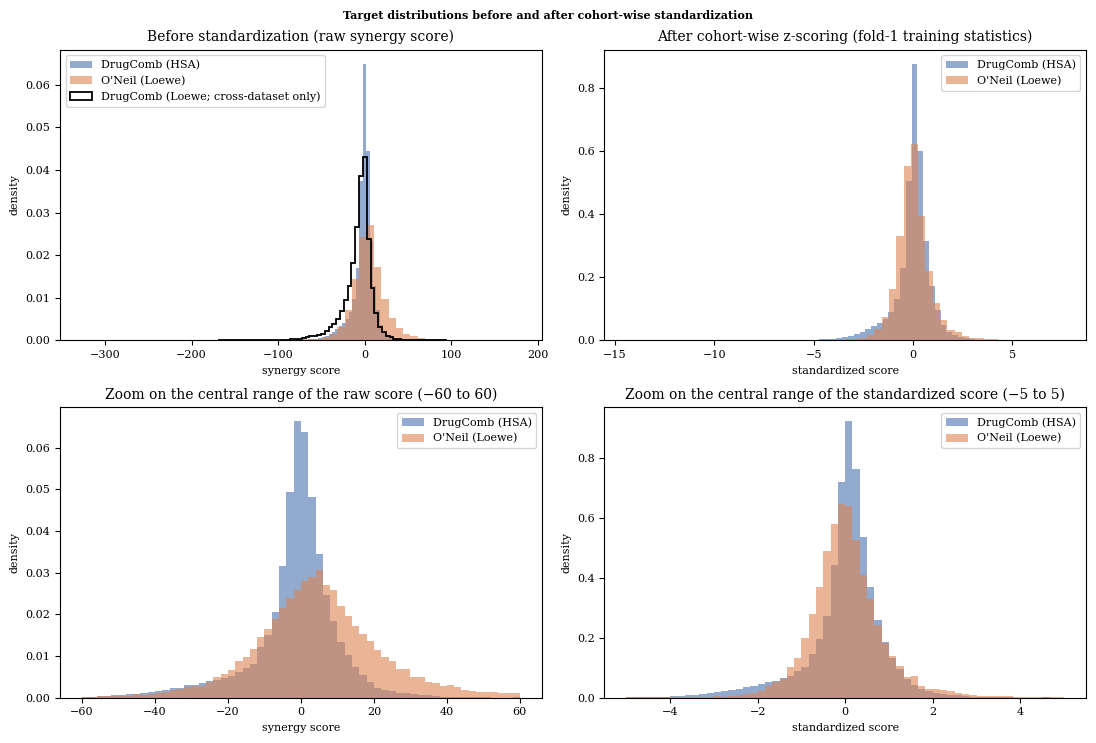


Before / after standardization (fold-1 statistics):
drugcomb  | raw: mean=  -1.67 median= -0.27 SD= 12.72 | after: mean=-0.014 SD=0.941
oneil     | raw: mean=   4.89 median=  4.25 SD= 22.70 | after: mean= 0.013 SD=0.990
(paper: DrugComb raw mean -1.67, median -0.27, SD 12.72, after -0.014 / 0.941; O'Neil raw mean 4.89, median 4.25, SD 22.70, after 0.013 / 0.990)


In [ ]:
# ===== Cell 23: Target distributions before and after standardization (Figure 2) =====
plt.rcParams.update({"font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 8,
                     "axes.titlesize": 8, "figure.titlesize": 8, "pdf.fonttype": 42, "ps.fonttype": 42})

fold1 = next(f for f in folds if f["fold"] == 1)
full_with_label = pd.concat([fold1["train_df"], fold1["val_df"], fold1["test_df"]], ignore_index=True)
assert len(full_with_label) == len(df_combined), "fold 1 does not cover the combined dataset"

STYLE = {"drugcomb": ("DrugComb (HSA)", "#4C72B0"), "oneil": ("O'Neil (Loewe)", "#DD8452")}
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for col_idx, (col, title, xlab) in enumerate([
        ("raw_target", "Before standardization (raw synergy score)", "synergy score"),
        ("label",      "After cohort-wise z-scoring (fold-1 training statistics)", "standardized score")]):
    for dtype, (name, color) in STYLE.items():
        vals = full_with_label.loc[full_with_label["dataset_type"] == dtype, col].dropna()
        axes[0, col_idx].hist(vals, bins=60, alpha=0.6, label=name, color=color, density=True)
    if col == "raw_target":                       # DrugComb Loewe score: used in the cross-dataset experiments only
        axes[0, col_idx].hist(pd.Series(xd_loewe).dropna(), bins=60, histtype="step", color="black", linewidth=1.3,
                              density=True, label="DrugComb (Loewe; cross-dataset only)")
    axes[0, col_idx].set_title(title, fontsize=10)
    axes[0, col_idx].set_xlabel(xlab); axes[0, col_idx].set_ylabel("density"); axes[0, col_idx].legend(fontsize=8)

for dtype, (name, color) in STYLE.items():
    sub = full_with_label[full_with_label["dataset_type"] == dtype]
    axes[1, 0].hist(sub["raw_target"], bins=60, range=(-60, 60), alpha=0.6, label=name, color=color, density=True)
    axes[1, 1].hist(sub["label"],      bins=60, range=(-5, 5),   alpha=0.6, label=name, color=color, density=True)
    out_raw = ((sub["raw_target"] < -60) | (sub["raw_target"] > 60)).mean() * 100
    out_z   = ((sub["label"] < -5) | (sub["label"] > 5)).mean() * 100
    print(f"{dtype:9s} | outside the zoomed range: raw(|x|>60)={out_raw:.2f}% | z(|z|>5)={out_z:.2f}%")
axes[1, 0].set_title("Zoom on the central range of the raw score (−60 to 60)", fontsize=10)
axes[1, 0].set_xlabel("synergy score"); axes[1, 0].set_ylabel("density"); axes[1, 0].legend(fontsize=8)
axes[1, 1].set_title("Zoom on the central range of the standardized score (−5 to 5)", fontsize=10)
axes[1, 1].set_xlabel("standardized score"); axes[1, 1].set_ylabel("density"); axes[1, 1].legend(fontsize=8)

fig.suptitle("Target distributions before and after cohort-wise standardization", weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "Standardization_Distribution.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "Standardization_Distribution.pdf", bbox_inches="tight")
plt.show()

print("\nBefore / after standardization (fold-1 statistics):")
for dtype in COHORTS:
    raw = full_with_label.loc[full_with_label["dataset_type"] == dtype, "raw_target"]
    lab = full_with_label.loc[full_with_label["dataset_type"] == dtype, "label"]
    print(f"{dtype:9s} | raw: mean={raw.mean():7.2f} median={raw.median():6.2f} SD={raw.std():6.2f} "
          f"| after: mean={lab.mean():6.3f} SD={lab.std():5.3f}")
print("(paper: DrugComb raw mean -1.67, median -0.27, SD 12.72, after -0.014 / 0.941; O'Neil raw mean 4.89, median 4.25, SD 22.70, after 0.013 / 0.990)")

In [ ]:
# ===== Cell 24: How different are the HSA and Loewe scores? (Reviewer 3, Comment 3) =====
# (a) DrugComb records of our subset that have both scores
both = pd.DataFrame({"hsa": drugcomb["synergy_hsa"].values, "loewe": xd_loewe}).dropna()
print(f"DrugComb subset      : n = {len(both):,} | Pearson {pearsonr(both.hsa, both.loewe)[0]:.3f} "
      f"| Spearman {spearmanr(both.hsa, both.loewe)[0]:.3f}   (paper: 61,099 | 0.449 | 0.509)")

# (b) the ONEIL study in the full DrugComb summary table (the same screen scored with both reference models)
full = pd.read_csv(DATA_DIR / "drugcomb_full_v1.5.csv", usecols=["study_name", "synergy_hsa", "synergy_loewe"], low_memory=False)
full["synergy_loewe"] = pd.to_numeric(full["synergy_loewe"], errors="coerce")
is_oneil_study = full["study_name"].astype(str).str.lower().str.contains(r"o['_ ]?neil", regex=True)
on_both = full.loc[is_oneil_study, ["synergy_hsa", "synergy_loewe"]].dropna()
print(f"ONEIL study (full table): n = {len(on_both):,} | Pearson {pearsonr(on_both.synergy_hsa, on_both.synergy_loewe)[0]:.3f} "
      f"| Spearman {spearmanr(on_both.synergy_hsa, on_both.synergy_loewe)[0]:.3f}   (paper: 92,208 | 0.600 | 0.731)")
del full

# (c) shape of the two score distributions on the DrugComb subset
for name, s in (("HSA", drugcomb["synergy_hsa"]), ("Loewe", both["loewe"])):
    z = (s - s.mean()) / s.std()
    print(f"{name:5s}: n={len(s):,} mean={s.mean():.2f} median={s.median():.2f} SD={s.std():.2f} | skew={s.skew():.2f} "
          f"excess kurtosis={s.kurt():.1f} | |z|>5: {(z.abs() > 5).mean() * 100:.2f}%")
print("(paper: HSA mean -1.67, median -0.27, SD 12.72, skew -1.08, excess kurtosis 7.0; Loewe mean -7.43, SD 16.49)")

DrugComb subset      : n = 61,099 | Pearson 0.449 | Spearman 0.509   (paper: 61,099 | 0.449 | 0.509)
ONEIL study (full table): n = 92,208 | Pearson 0.600 | Spearman 0.731   (paper: 92,208 | 0.600 | 0.731)
HSA  : n=61,111 mean=-1.67 median=-0.27 SD=12.72 | skew=-1.08 excess kurtosis=7.0 | |z|>5: 0.23%
Loewe: n=61,099 mean=-7.43 median=-4.24 SD=16.49 | skew=-1.16 excess kurtosis=4.6 | |z|>5: 0.18%
(paper: HSA mean -1.67, median -0.27, SD 12.72, skew -1.08, excess kurtosis 7.0; Loewe mean -7.43, SD 16.49)


In [ ]:
# ===== Cell 25: Dataset documentation (Reviewer 3, Comment 4; Table 1, Table 2, Supplementary Table S1) =====
funnel = []
def _add(cohort, stage, rows, drugs=None):
    funnel.append({"cohort": cohort, "stage": stage, "rows": rows, "unique_drugs": drugs})

# --- DrugComb: from the raw file to the retained subset ---
_raw = pd.read_csv(DATA_DIR / "drugcomb_full_v1.5.csv", usecols=DRUGCOMB_COLS, low_memory=False)
_add("drugcomb", "raw file (6 selected columns)", len(_raw))
_cancer = _raw[~_raw["study_name"].astype(str).str.lower().str.contains("|".join(NON_ONCOLOGY_KEYWORDS), na=False)]
_add("drugcomb", "after removing non-cancer studies (study_name keywords)", len(_cancer))
_complete = _cancer.dropna(subset=["synergy_hsa", "cell_line_name"])
_add("drugcomb", "after removing rows with missing HSA score or cell line", len(_complete),
     len(set(_complete["drug_row"]) | set(_complete["drug_col"])))
del _raw, _cancer, _complete
_d1 = set(drugcomb["drug_row"]) | set(drugcomb["drug_col"])
_add("drugcomb", "rows whose two drugs both have a retrieved SMILES (retained)", len(drugcomb), len(_d1))

# --- O'Neil ---
_has = oneil["drug_row"].map(drug_to_smiles).notna() & oneil["drug_col"].map(drug_to_smiles).notna()
_add("oneil", "raw summary rows", len(oneil), pd.concat([oneil["drug_row"], oneil["drug_col"]]).nunique())
_add("oneil", "rows whose two drugs both have a SMILES", int(_has.sum()),
     pd.concat([oneil.loc[_has, "drug_row"], oneil.loc[_has, "drug_col"]]).nunique())
_oc = df_combined[df_combined["dataset_type"] == "oneil"]
_add("oneil", "rows with a non-missing Loewe score (retained)", len(_oc), pd.concat([_oc["drug_1"], _oc["drug_2"]]).nunique())
funnel_df = pd.DataFrame(funnel)
print("Dataset construction funnel (paper: 1,432,351 -> 1,432,146 -> 4,608 compounds -> 61,111 records / 276 drugs; O'Neil 22,737 / 38):")
print(funnel_df.to_string(index=False))

# --- Final counts ---
print("\nFinal counts (combined dataset; paper: 83,848 records, 309 compounds, 251 raw / 246 normalized cell lines):")
_cnt = []
for dtype in ("drugcomb", "oneil", "all"):
    d = df_combined if dtype == "all" else df_combined[df_combined["dataset_type"] == dtype]
    d1, d2 = d["drug_1"].astype(str).values, d["drug_2"].astype(str).values
    pair = pd.Series(np.where(d1 <= d2, d1 + "|" + d2, d2 + "|" + d1))
    d = d.reset_index(drop=True)
    _cnt.append({"cohort": dtype, "rows": len(d), "unique_drugs": len(set(d["drug_1"]) | set(d["drug_2"])),
                 "unique_drug_pairs": pair.nunique(), "cell_lines_raw": d["cell_line"].nunique(),
                 "cell_lines_normalized": d["cell_line"].map(_norm_name).nunique(),
                 "unique_pair_cell_combos_by_structure": _combo_keys(d).nunique()})
print(pd.DataFrame(_cnt).to_string(index=False))
print("(paper: DrugComb 50,091 distinct (drug pair, cell line) combinations by structure -> about 11,020 repeated measurements)")

# --- Partition sizes of every fold (every record is in exactly one of the three partitions) ---
part = []
for f in folds:
    tr_drugs = set(f["train_df"]["drug_1"]) | set(f["train_df"]["drug_2"])
    for dtype in ("drugcomb", "oneil", "all"):
        c = (lambda x: len(x)) if dtype == "all" else (lambda x, t=dtype: int((x["dataset_type"] == t).sum()))
        part.append({"fold": f["fold"], "cohort": dtype, "train_rows": c(f["train_df"]), "val_rows": c(f["val_df"]),
                     "test_rows": c(f["test_df"]), "train_drugs": len(tr_drugs),
                     "val_drugs": f["n_val_drugs"], "test_drugs": f["n_test_drugs"]})
part_df = pd.DataFrame(part)
print("\nPartition sizes:")
print(part_df.to_string(index=False))
for dtype in ("drugcomb", "oneil", "all"):
    tot = int((df_combined["dataset_type"] == dtype).sum()) if dtype != "all" else len(df_combined)
    s = part_df[part_df["cohort"] == dtype][["train_rows", "val_rows", "test_rows"]].sum(axis=1)
    assert (s == tot).all(), f"the partitions do not add up to the total ({tot}) for {dtype}"
print("✓ in every fold train + validation + test = all records (every cohort and overall)")

# --- SMILES and structures ---
_dr  = sorted(set(all_drugs))
_smi = {d: drug_to_smiles.get(d) for d in _dr}
_ok  = {d: s for d, s in _smi.items() if isinstance(s, str) and s}
print("\nSMILES and structures (paper: 309 compounds, none failed to parse; 146 with stereo marks):")
print(f"  unique compounds: {len(_dr)} | without SMILES: {len(_dr) - len(_ok)} "
      f"| SMILES rejected by RDKit: {sum(1 for s in _ok.values() if Chem.MolFromSmiles(s) is None)} "
      f"| without ChemBERTa embedding: {sum(1 for d in _dr if d not in drug_to_chemberta)}")
print(f"  with stereo marks (@ / \\): {sum(1 for s in _ok.values() if any(ch in s for ch in ['@', '/', chr(92)]))} "
      f"| multi-component (salt / mixture, contains '.'): {sum(1 for s in _ok.values() if '.' in s)}")
print(f"  distinct structures after removing stereochemistry: {len({_drug_key(d) for d in _dr})} of {len(_dr)} names")
try:
    _tok = AutoTokenizer.from_pretrained(CHEMBERTA_NAME)
    _long = sum(1 for s in _ok.values() if len(_tok(s)["input_ids"]) > 128)
    print(f"  SMILES with more than 128 tokens (truncated for ChemBERTa): {_long} of {len(_dr)}")
except Exception as e:
    print("  (token lengths not counted:", type(e).__name__, ")")

funnel_df.to_csv(XD_OUT / "dataset_documentation_funnel.csv", index=False)
part_df.to_csv(XD_OUT / "dataset_documentation_partitions.csv", index=False)

Dataset construction funnel (paper: 1,432,351 -> 1,432,146 -> 4,608 compounds -> 61,111 records / 276 drugs; O'Neil 22,737 / 38):
  cohort                                                        stage    rows  unique_drugs
drugcomb                                raw file (6 selected columns) 1432351           NaN
drugcomb      after removing non-cancer studies (study_name keywords) 1432146           NaN
drugcomb      after removing rows with missing HSA score or cell line 1432146        4608.0
drugcomb rows whose two drugs both have a retrieved SMILES (retained)   61111         276.0
   oneil                                             raw summary rows   22737          38.0
   oneil                      rows whose two drugs both have a SMILES   22737          38.0
   oneil               rows with a non-missing Loewe score (retained)   22737          38.0

Final counts (combined dataset; paper: 83,848 records, 309 compounds, 251 raw / 246 normalized cell lines):
  cohort  rows  unique_dr

config.json:   0%|          | 0.00/501 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/166 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/9.43k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.21k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

  SMILES with more than 128 tokens (truncated for ChemBERTa): 9 of 309
